# E-Commerce Order Fulfillment & Shipping Performance Analysis

An evidence-led analysis of order-to-door delivery performance using the Brazilian E-Commerce Public Dataset by Olist. The notebook uses the real order and customer tables in `../data/raw/`; it does not infer unavailable carrier, shipping-mode, or warehouse identifiers.

## Dataset, definitions, and scope

The source describes approximately 100,000 anonymized Olist orders from 2016–2018. This project uses `olist_orders_dataset.csv` and `olist_customers_dataset.csv`, downloaded from the public Olist dataset mirror at [spdrio/Brazilian-E-Commerce-Public-Dataset-by-Olist](https://github.com/spdrio/Brazilian-E-Commerce-Public-Dataset-by-Olist), commit `fa0cc6d1aff713d3c8b9a1e633b56889881848bf`. The original dataset page is [Kaggle: Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce); its listed license is CC BY-NC-SA 4.0. Attribute Olist and review the license before reuse.

Delivery duration is elapsed days from purchase timestamp to customer-delivery timestamp. The analysis cohort consists of rows marked `delivered` with valid purchase, actual-delivery, and estimated-delivery timestamps, and a non-negative duration. On-time is defined by calendar date: actual delivery date is on or before the estimated delivery date. This date-level comparison avoids treating a same-day arrival after midnight as late when the estimate is date-only. On-time and delayed percentages use only the eligible cohort. Total orders count unique order IDs across all statuses; eligible, excluded, on-time, and delayed counts are reported separately and reconciled.

Weekday/weekend refers to the customer delivery day. Monthly trends are grouped by purchase month (order cohorts). November–December is only a peak-season proxy, not a verified holiday flag. Brazilian seasons are meteorological seasons in the Southern Hemisphere. State-to-macroregion mapping follows the standard Brazilian UF grouping. The downloaded order/customer tables do not include carrier IDs, shipping modes, warehouse IDs, or state boundary geometries.

## Load dataset and configure analysis

Paths resolve from either the project root or the `notebooks` folder.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
CHART_DIR = PROJECT_ROOT / 'outputs' / 'charts'
CHART_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 300, 'axes.titlesize': 14, 'axes.labelsize': 11})

orders_raw = pd.read_csv(RAW_DIR / 'olist_orders_dataset.csv')
customers_raw = pd.read_csv(RAW_DIR / 'olist_customers_dataset.csv')
print(f'Orders table: {orders_raw.shape[0]:,} rows x {orders_raw.shape[1]} columns')
print(f'Customers table: {customers_raw.shape[0]:,} rows x {customers_raw.shape[1]} columns')
print('\nOrder columns:', orders_raw.columns.tolist())
print('Customer columns:', customers_raw.columns.tolist())

Orders table: 99,441 rows x 8 columns
Customers table: 99,441 rows x 5 columns

Order columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
Customer columns: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']


## Data understanding

Inspect actual dimensions, schema, data types, descriptive summaries, missing values, and duplicate keys before calculating performance.

In [2]:
## Data understanding

print('Order data types:')
display(orders_raw.dtypes.to_frame('dtype'))
print('Order statistical summary:')
display(orders_raw.describe(include='all').T)
print('Missing values by order column:')
display(orders_raw.isna().sum().sort_values(ascending=False).to_frame('missing'))
print('Exact duplicate rows:', int(orders_raw.duplicated().sum()))
print('Duplicate order IDs:', int(orders_raw['order_id'].duplicated().sum()))
print('\nCustomer data types:')
display(customers_raw.dtypes.to_frame('dtype'))
print('Missing values by customer column:')
display(customers_raw.isna().sum().sort_values(ascending=False).to_frame('missing'))
print('Exact duplicate customer rows:', int(customers_raw.duplicated().sum()))
print('Duplicate customer IDs:', int(customers_raw['customer_id'].duplicated().sum()))

Order data types:


,dtype
order_id,str
customer_id,str
order_status,str
order_purchase_timestamp,str
order_approved_at,str
order_delivered_carrier_date,str
order_delivered_customer_date,str
order_estimated_delivery_date,str


Order statistical summary:


,count,unique,top,freq
order_id,99441,99441,e481f51cbdc54678b7cc49136f2d6af7,1
customer_id,99441,99441,9ef432eb6251297304e76186b10a928d,1
order_status,99441,8,delivered,96478
order_purchase_timestamp,99441,98875,2018-03-31 15:08:21,3
order_approved_at,99281,90733,2018-02-27 04:31:10,9
order_delivered_carrier_date,97658,81018,2018-05-09 15:48:00,47
order_delivered_customer_date,96476,95664,2018-05-14 20:02:44,3
order_estimated_delivery_date,99441,459,2017-12-20 00:00:00,522


Missing values by order column:


,missing
order_delivered_customer_date,2965
order_delivered_carrier_date,1783
order_approved_at,160
order_id,0
order_purchase_timestamp,0
order_status,0
customer_id,0
order_estimated_delivery_date,0


Exact duplicate rows: 0
Duplicate order IDs: 0

Customer data types:


,dtype
customer_id,str
customer_unique_id,str
customer_zip_code_prefix,int64
customer_city,str
customer_state,str


Missing values by customer column:


,missing
customer_id,0
customer_unique_id,0
customer_zip_code_prefix,0
customer_city,0
customer_state,0


Exact duplicate customer rows: 0
Duplicate customer IDs: 0


## Data cleaning and shipping KPIs

Parse timestamps, preserve valid records, define the delivered-order cohort, and reconcile eligible and excluded orders.

In [3]:
## Cleaning, cohort definition, and KPI calculations

date_columns = [
    'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
    'order_delivered_customer_date', 'order_estimated_delivery_date'
]
orders = orders_raw.copy()
customers = customers_raw.copy()
orders['order_status'] = orders['order_status'].astype('string').str.strip().str.lower()
customers['customer_state'] = customers['customer_state'].astype('string').str.strip().str.upper()
for column in date_columns:
    orders[column] = pd.to_datetime(orders[column], errors='coerce')

if not orders['order_id'].is_unique:
    raise ValueError('Expected one row per order_id; investigate duplicate order IDs before analysis.')
if not customers['customer_id'].is_unique:
    raise ValueError('Expected unique customer_id values in the customer dimension.')

orders['delivery_duration_days'] = (
    orders['order_delivered_customer_date'] - orders['order_purchase_timestamp']
).dt.total_seconds() / 86400
delivered_mask = orders['order_status'].eq('delivered')
required_dates_present = orders[[
    'order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date'
]].notna().all(axis=1)
valid_duration = orders['delivery_duration_days'].ge(0)
eligible_mask = delivered_mask & required_dates_present & valid_duration
eligible = orders.loc[eligible_mask].copy()
eligible['is_late'] = (
    eligible['order_delivered_customer_date'].dt.normalize()
    > eligible['order_estimated_delivery_date'].dt.normalize()
)
eligible['is_on_time'] = ~eligible['is_late']
eligible['shipping_delay_days'] = (
    eligible['order_delivered_customer_date'].dt.normalize()
    - eligible['order_estimated_delivery_date'].dt.normalize()
).dt.days.clip(lower=0)
eligible['delivery_weekday'] = eligible['order_delivered_customer_date'].dt.day_name()
eligible['delivery_dayofweek'] = eligible['order_delivered_customer_date'].dt.day_of_week
eligible['delivery_period'] = np.where(eligible['delivery_dayofweek'] >= 5, 'Weekend', 'Weekday')
eligible['purchase_month'] = eligible['order_purchase_timestamp'].dt.to_period('M').dt.to_timestamp()
eligible['purchase_month_name'] = eligible['order_purchase_timestamp'].dt.month_name()
eligible['purchase_month_num'] = eligible['order_purchase_timestamp'].dt.month
season_by_month = {12: 'Summer', 1: 'Summer', 2: 'Summer', 3: 'Autumn', 4: 'Autumn', 5: 'Autumn',
                   6: 'Winter', 7: 'Winter', 8: 'Winter', 9: 'Spring', 10: 'Spring', 11: 'Spring'}
eligible['purchase_season'] = eligible['purchase_month_num'].map(season_by_month)
eligible['peak_season_proxy'] = np.where(eligible['purchase_month_num'].isin([11, 12]), 'Nov-Dec proxy', 'Other months')

total_orders = int(orders['order_id'].nunique())
total_on_time = int(eligible['is_on_time'].sum())
total_delayed = int(eligible['is_late'].sum())
eligible_count = int(len(eligible))
excluded_from_kpis = total_orders - eligible_count
kpis = pd.Series({
    'Total orders (all statuses)': total_orders,
    'Eligible delivered orders': eligible_count,
    'Orders excluded from delivery KPIs': excluded_from_kpis,
    'Total on-time orders': total_on_time,
    'Total delayed orders': total_delayed,
    'On-time delivery rate (%)': 100 * total_on_time / eligible_count if eligible_count else np.nan,
    'Delayed delivery (%)': 100 * total_delayed / eligible_count if eligible_count else np.nan,
    'Average delivery duration (days)': eligible['delivery_duration_days'].mean(),
    'Average delay among delayed orders (days)': eligible.loc[eligible['is_late'], 'shipping_delay_days'].mean(),
}, name='value')

analysis = eligible.merge(
    customers[['customer_id', 'customer_state']], on='customer_id', how='left', validate='many_to_one'
)
print('Cleaning summary')
print(f'  Delivered status rows: {int(delivered_mask.sum()):,}')
print(f'  Eligible delivered cohort: {eligible_count:,}')
print(f'  Delivered rows excluded for missing/invalid required dates or negative duration: {int(delivered_mask.sum()) - eligible_count:,}')
print(f'  All-status orders outside eligible cohort: {excluded_from_kpis:,}')
print(f'  Eligible rows without a matched customer state: {int(analysis["customer_state"].isna().sum()):,}')
print('\nKPI summary:')
display(kpis.to_frame())
assert total_on_time + total_delayed == eligible_count, 'On-time and delayed counts must reconcile to eligible orders.'
assert total_orders == eligible_count + excluded_from_kpis, 'Eligible and excluded orders must reconcile to all orders.'
print('Reconciliation checks passed.')

Cleaning summary
  Delivered status rows: 96,478
  Eligible delivered cohort: 96,470
  Delivered rows excluded for missing/invalid required dates or negative duration: 8
  All-status orders outside eligible cohort: 2,971
  Eligible rows without a matched customer state: 0

KPI summary:


,value
Total orders (all statuses),99441.000000
Eligible delivered orders,96470.000000
Orders excluded from delivery KPIs,2971.000000
Total on-time orders,89936.000000
Total delayed orders,6534.000000
On-time delivery rate (%),93.226910
Delayed delivery (%),6.773090
Average delivery duration (days),12.558217
Average delay among delayed orders (days),10.620141


Reconciliation checks passed.


## Overall delivery performance

Summarize the KPIs, delivery-duration distribution, and on-time versus delayed outcomes with evidence-based observations.

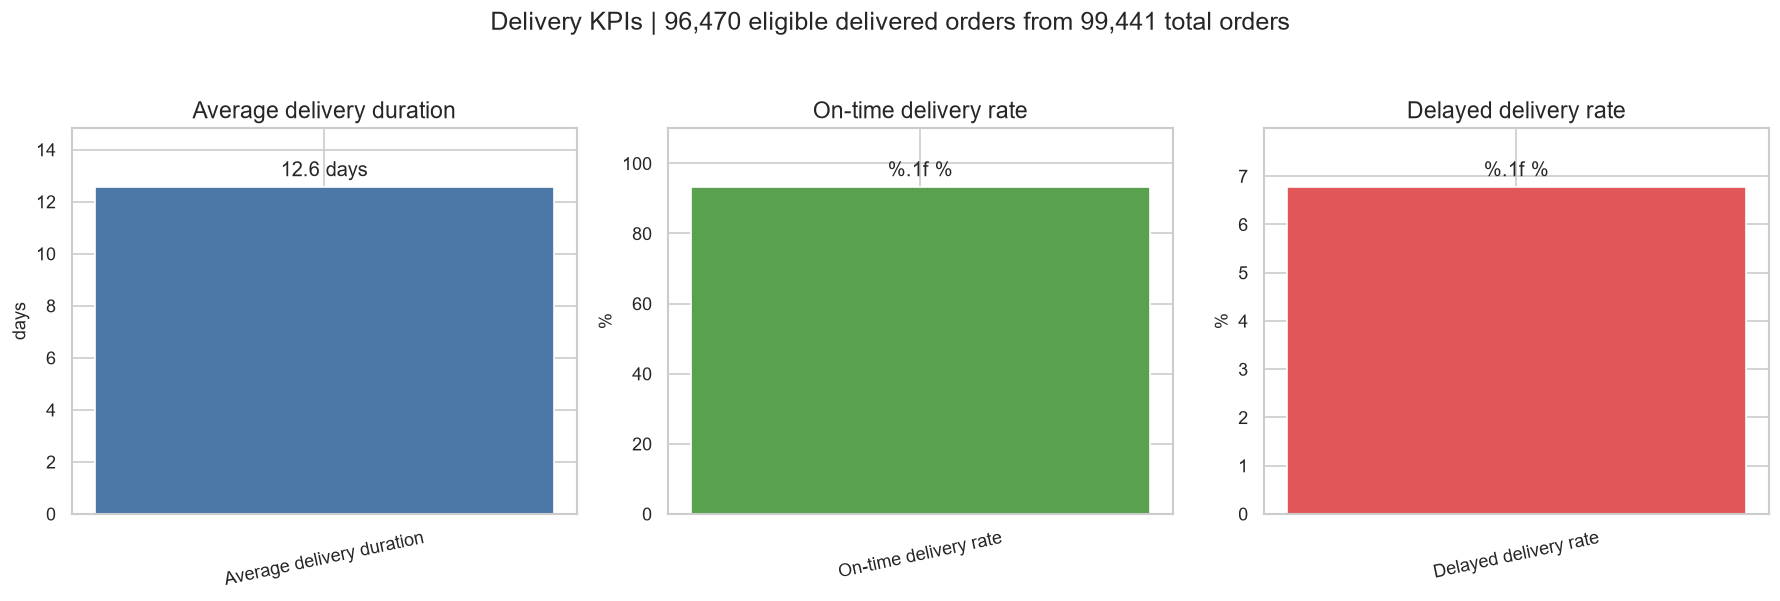

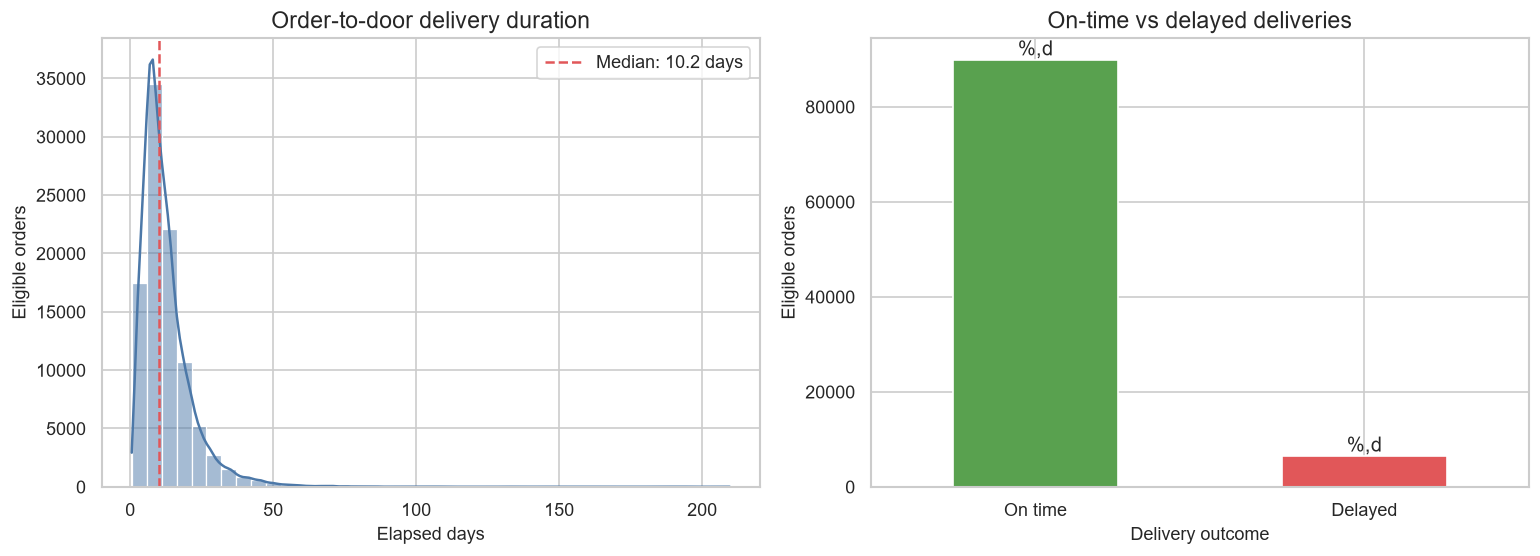

The eligible cohort averages 12.56 days from purchase to customer delivery.
93.2% arrive by the estimated calendar date; 6.8% arrive later.
The 2,971 non-eligible orders are not treated as on-time or delayed in these rates.


In [4]:
## Overall performance and distribution

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
kpi_chart = [
    ('Average delivery duration', float(kpis['Average delivery duration (days)']), 'days', '#4C78A8'),
    ('On-time delivery rate', float(kpis['On-time delivery rate (%)']), '%', '#59A14F'),
    ('Delayed delivery rate', float(kpis['Delayed delivery (%)']), '%', '#E15759'),
]
for ax, (title, value, unit, color) in zip(axes, kpi_chart):
    ax.bar([title], [value], color=color, width=0.58)
    ax.set_title(title)
    ax.set_ylabel(unit)
    ax.tick_params(axis='x', labelrotation=12)
    ax.bar_label(ax.containers[0], fmt=f'%.1f {unit}', padding=4)
    ax.set_ylim(0, max(value * 1.18, 1))
fig.suptitle(f'Delivery KPIs | {eligible_count:,} eligible delivered orders from {total_orders:,} total orders', y=1.04, fontsize=15)
fig.tight_layout()
fig.savefig(CHART_DIR / 'kpi_summary.png', dpi=300, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.histplot(eligible['delivery_duration_days'], bins=40, kde=True, ax=axes[0], color='#4C78A8')
axes[0].set(title='Order-to-door delivery duration', xlabel='Elapsed days', ylabel='Eligible orders')
axes[0].axvline(eligible['delivery_duration_days'].median(), color='#E15759', linestyle='--', label=f'Median: {eligible["delivery_duration_days"].median():.1f} days')
axes[0].legend()
status_counts = pd.Series({'On time': total_on_time, 'Delayed': total_delayed})
status_counts.plot(kind='bar', ax=axes[1], color=['#59A14F', '#E15759'])
axes[1].set(title='On-time vs delayed deliveries', xlabel='Delivery outcome', ylabel='Eligible orders')
axes[1].tick_params(axis='x', rotation=0)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%,d')
fig.tight_layout()
fig.savefig(CHART_DIR / 'duration_and_delivery_outcomes.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"The eligible cohort averages {kpis['Average delivery duration (days)']:.2f} days from purchase to customer delivery.")
print(f"{kpis['On-time delivery rate (%)']:.1f}% arrive by the estimated calendar date; {kpis['Delayed delivery (%)']:.1f}% arrive later.")
print(f"The {total_orders - eligible_count:,} non-eligible orders are not treated as on-time or delayed in these rates.")

## Weekday and weekend delivery performance

Group outcomes by the actual customer delivery day and compare weekday/weekend rates.

,orders,average_duration_days,on_time_rate,on_time_rate_pct
delivery_weekday,,,,
Monday,18892,12.79,0.94,94.18
Tuesday,18492,13.10,0.93,93.36
Wednesday,18056,12.66,0.93,93.15
Thursday,17097,12.20,0.93,93.31
Friday,17264,11.77,0.93,93.45
Saturday,5463,12.69,0.90,89.82
Sunday,1206,14.74,0.88,88.47


,orders,average_duration_days,on_time_rate,on_time_rate_pct
delivery_period,,,,
Weekday,89801,12.52,0.93,93.50
Weekend,6669,13.06,0.90,89.58


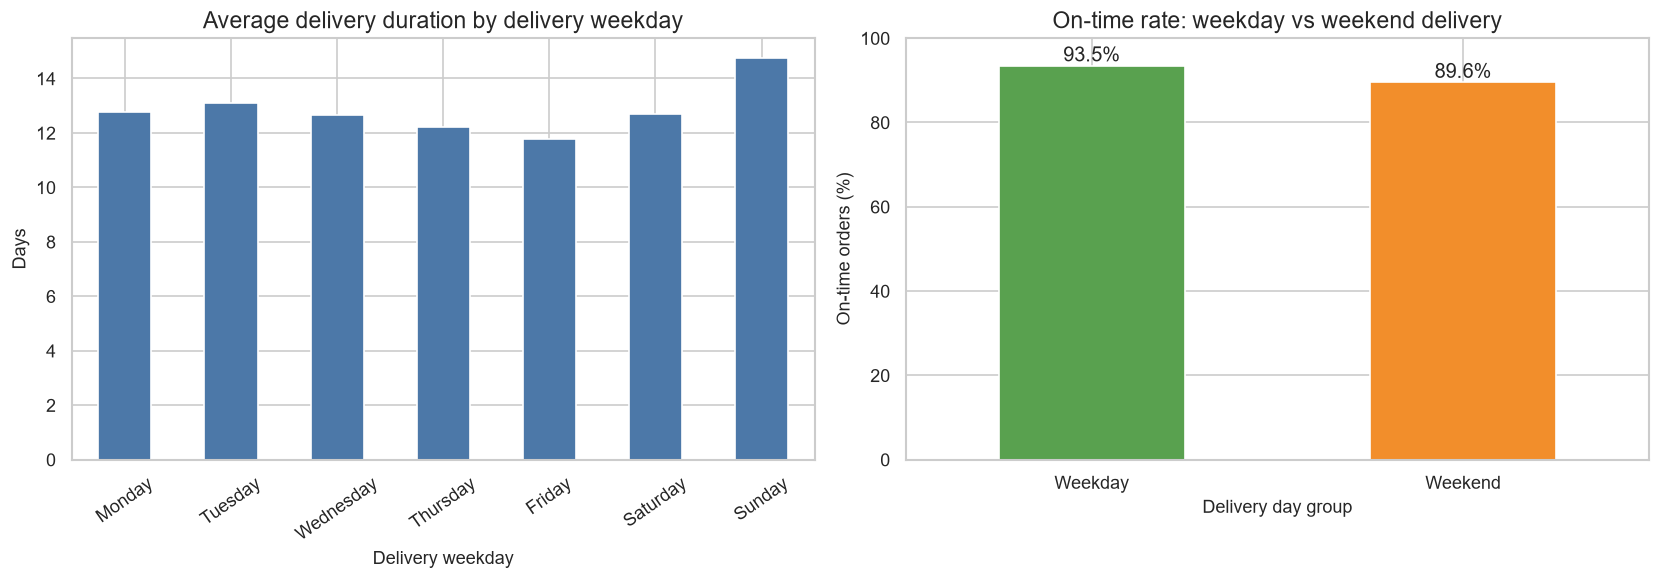

Friday has the shortest average duration (11.77 days); Sunday has the longest (14.74 days).
Weekday: 89,801 deliveries, 12.52 average days, 93.5% on time.
Weekend: 6,669 deliveries, 13.06 average days, 89.6% on time.
Operational follow-up: compare weekend staffing and handoff schedules only if the weekend gap is material in these observed outcomes.


In [5]:
## Delivery weekday and weekend comparison

weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_summary = eligible.groupby('delivery_weekday').agg(
    orders=('order_id', 'nunique'),
    average_duration_days=('delivery_duration_days', 'mean'),
    on_time_rate=('is_on_time', 'mean'),
).reindex(weekday_order)
weekday_summary['on_time_rate_pct'] = 100 * weekday_summary['on_time_rate']
period_summary = eligible.groupby('delivery_period').agg(
    orders=('order_id', 'nunique'),
    average_duration_days=('delivery_duration_days', 'mean'),
    on_time_rate=('is_on_time', 'mean'),
)
period_summary['on_time_rate_pct'] = 100 * period_summary['on_time_rate']
display(weekday_summary.round(2))
display(period_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
weekday_summary['average_duration_days'].plot(kind='bar', ax=axes[0], color='#4C78A8')
axes[0].set(title='Average delivery duration by delivery weekday', xlabel='Delivery weekday', ylabel='Days')
axes[0].tick_params(axis='x', rotation=35)
period_summary['on_time_rate_pct'].reindex(['Weekday', 'Weekend']).plot(kind='bar', ax=axes[1], color=['#59A14F', '#F28E2B'])
axes[1].set(title='On-time rate: weekday vs weekend delivery', xlabel='Delivery day group', ylabel='On-time orders (%)')
axes[1].tick_params(axis='x', rotation=0)
axes[1].set_ylim(0, 100)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.1f%%')
fig.tight_layout()
fig.savefig(CHART_DIR / 'weekday_weekend_performance.png', dpi=300, bbox_inches='tight')
plt.show()

best_weekday = weekday_summary['average_duration_days'].idxmin()
worst_weekday = weekday_summary['average_duration_days'].idxmax()
print(f'{best_weekday} has the shortest average duration ({weekday_summary.loc[best_weekday, "average_duration_days"]:.2f} days); {worst_weekday} has the longest ({weekday_summary.loc[worst_weekday, "average_duration_days"]:.2f} days).')
for period in ['Weekday', 'Weekend']:
    if period in period_summary.index:
        row = period_summary.loc[period]
        print(f'{period}: {int(row["orders"]):,} deliveries, {row["average_duration_days"]:.2f} average days, {row["on_time_rate_pct"]:.1f}% on time.')
print('Operational follow-up: compare weekend staffing and handoff schedules only if the weekend gap is material in these observed outcomes.')

## Monthly and seasonal trends

Use purchase-month cohorts, Southern Hemisphere seasons, and an explicitly labeled November–December peak-season proxy.

,orders,average_duration_days,on_time_rate,on_time_rate_pct
purchase_month,,,,
2016-09-01,1,54.81,0.00,0.00
2016-10-01,265,19.60,0.99,99.25
2016-12-01,1,4.69,1.00,100.00
2017-01-01,750,12.65,0.97,97.07
2017-02-01,1653,13.17,0.97,97.04
2017-03-01,2546,12.95,0.95,95.44
2017-04-01,2303,14.92,0.93,93.44
2017-05-01,3545,11.32,0.97,97.01
2017-06-01,3135,12.01,0.97,96.97


,orders,average_duration_days,on_time_rate,on_time_rate_pct
purchase_season,,,,
Summer,21541,15.17,0.92,91.59
Autumn,28944,13.02,0.92,91.54
Winter,29803,9.73,0.97,96.65
Spring,16182,13.47,0.92,92.11


,orders,average_duration_days,on_time_rate,on_time_rate_pct
peak_season_proxy,,,,
Nov-Dec proxy,12802,15.26,0.90,89.73
Other months,83668,12.14,0.94,93.76


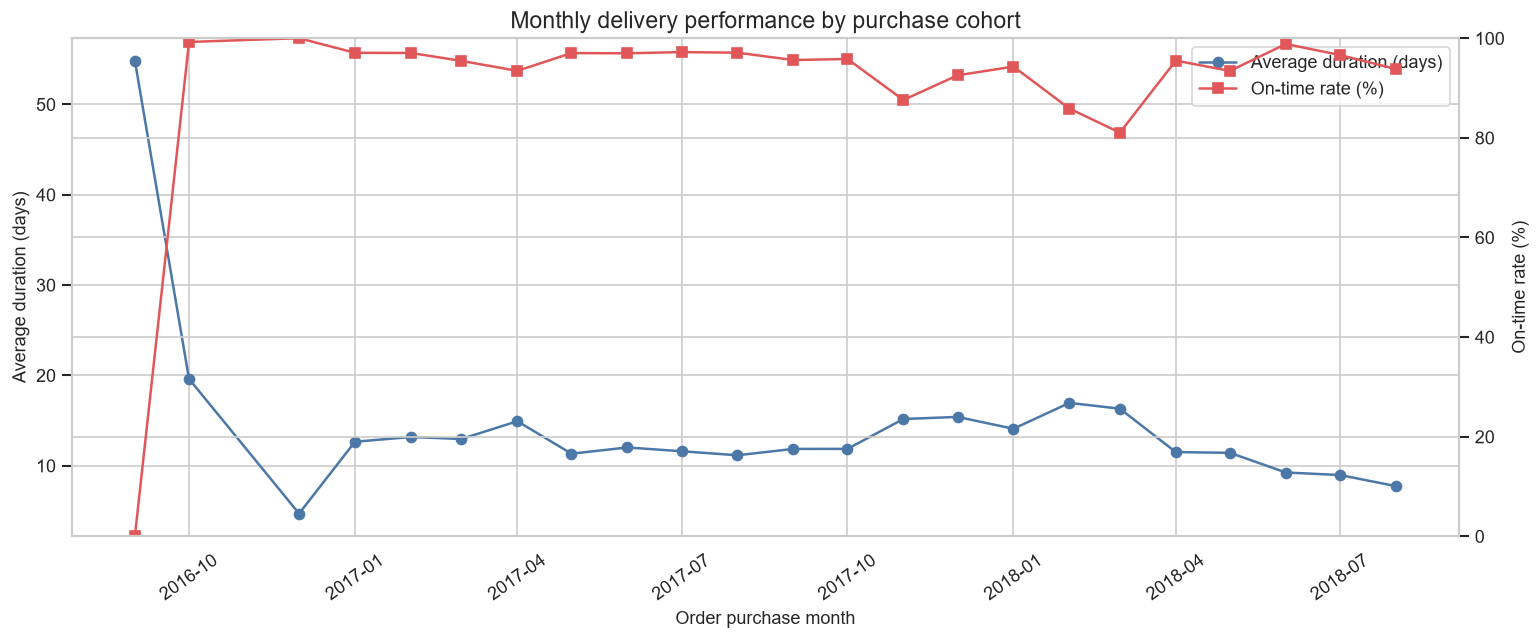

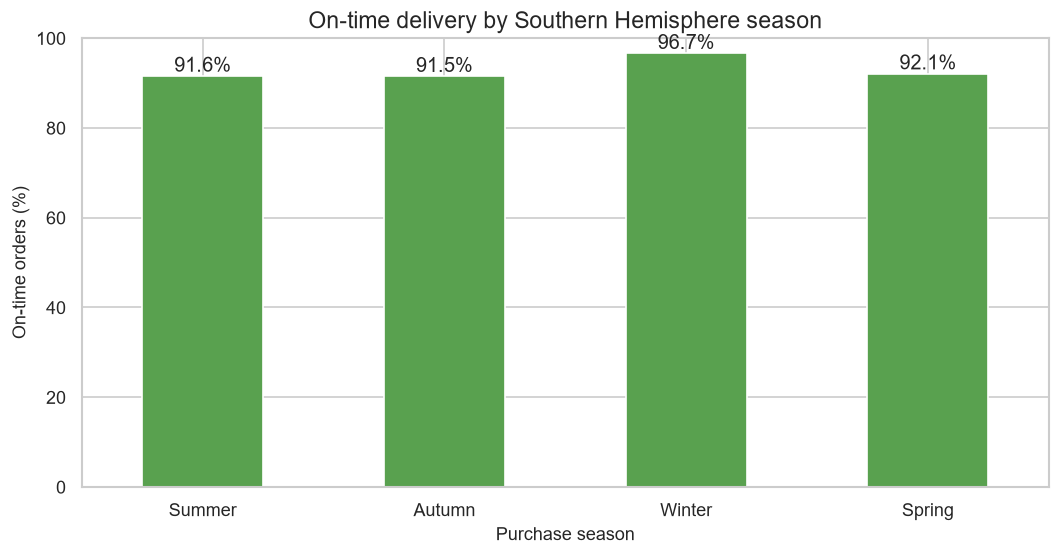

Highest observed monthly on-time rate: 2016-12 (100.0%, 1 orders).
Lowest observed monthly on-time rate: 2016-09 (0.0%, 1 orders).
Nov-Dec peak-season proxy: 12,802 orders, 15.26 average days, 89.7% on time; other months: 83,668 orders, 12.14 days, 93.8% on time.
Treat this as a seasonal comparison, not proof of a holiday effect; purchase month is the available proxy.


In [6]:
## Monthly and seasonal delivery trends

monthly_summary = eligible.groupby('purchase_month').agg(
    orders=('order_id', 'nunique'),
    average_duration_days=('delivery_duration_days', 'mean'),
    on_time_rate=('is_on_time', 'mean'),
)
monthly_summary['on_time_rate_pct'] = 100 * monthly_summary['on_time_rate']
season_summary = eligible.groupby('purchase_season').agg(
    orders=('order_id', 'nunique'),
    average_duration_days=('delivery_duration_days', 'mean'),
    on_time_rate=('is_on_time', 'mean'),
)
season_summary['on_time_rate_pct'] = 100 * season_summary['on_time_rate']
peak_summary = eligible.groupby('peak_season_proxy').agg(
    orders=('order_id', 'nunique'),
    average_duration_days=('delivery_duration_days', 'mean'),
    on_time_rate=('is_on_time', 'mean'),
)
peak_summary['on_time_rate_pct'] = 100 * peak_summary['on_time_rate']
display(monthly_summary.round(2))
display(season_summary.reindex(['Summer', 'Autumn', 'Winter', 'Spring']).round(2))
display(peak_summary.round(2))

fig, ax1 = plt.subplots(figsize=(13, 5.5))
ax1.plot(monthly_summary.index, monthly_summary['average_duration_days'], marker='o', color='#4C78A8', label='Average duration (days)')
ax1.set(xlabel='Order purchase month', ylabel='Average duration (days)', title='Monthly delivery performance by purchase cohort')
ax2 = ax1.twinx()
ax2.plot(monthly_summary.index, monthly_summary['on_time_rate_pct'], marker='s', color='#E15759', label='On-time rate (%)')
ax2.set_ylabel('On-time rate (%)')
ax2.set_ylim(0, 100)
ax1.tick_params(axis='x', rotation=35)
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [line.get_label() for line in lines], loc='best')
fig.tight_layout()
fig.savefig(CHART_DIR / 'monthly_delivery_trends.png', dpi=300, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.8))
season_order = ['Summer', 'Autumn', 'Winter', 'Spring']
season_summary['on_time_rate_pct'].reindex(season_order).plot(kind='bar', ax=ax, color='#59A14F')
ax.set(title='On-time delivery by Southern Hemisphere season', xlabel='Purchase season', ylabel='On-time orders (%)', ylim=(0, 100))
ax.tick_params(axis='x', rotation=0)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%')
fig.tight_layout()
fig.savefig(CHART_DIR / 'seasonal_delivery_performance.png', dpi=300, bbox_inches='tight')
plt.show()

best_month = monthly_summary['on_time_rate_pct'].idxmax()
worst_month = monthly_summary['on_time_rate_pct'].idxmin()
print(f'Highest observed monthly on-time rate: {best_month:%Y-%m} ({monthly_summary.loc[best_month, "on_time_rate_pct"]:.1f}%, {int(monthly_summary.loc[best_month, "orders"]):,} orders).')
print(f'Lowest observed monthly on-time rate: {worst_month:%Y-%m} ({monthly_summary.loc[worst_month, "on_time_rate_pct"]:.1f}%, {int(monthly_summary.loc[worst_month, "orders"]):,} orders).')
if {'Nov-Dec proxy', 'Other months'}.issubset(peak_summary.index):
    peak = peak_summary.loc['Nov-Dec proxy']
    other = peak_summary.loc['Other months']
    print(f"Nov-Dec peak-season proxy: {int(peak['orders']):,} orders, {peak['average_duration_days']:.2f} average days, {peak['on_time_rate_pct']:.1f}% on time; other months: {int(other['orders']):,} orders, {other['average_duration_days']:.2f} days, {other['on_time_rate_pct']:.1f}% on time.")
    print('Treat this as a seasonal comparison, not proof of a holiday effect; purchase month is the available proxy.')

## Shipping mode, carrier, and warehouse availability

Test candidate fields in the loaded schema. Do not infer carrier performance from a carrier-delivery timestamp.

In [7]:
## Shipping mode, carrier, and warehouse field availability

available_columns = set(orders.columns) | set(customers.columns)
candidate_fields = {
    'Shipping mode': ['shipping_mode', 'ship_mode'],
    'Carrier identifier': ['carrier_id', 'carrier', 'shipping_carrier'],
    'Warehouse or fulfillment center': ['warehouse_id', 'warehouse', 'fulfillment_center_id'],
}
for label, candidates in candidate_fields.items():
    present = [column for column in candidates if column in available_columns]
    if present:
        print(f'{label}: available columns {present}')
    else:
        print(f'{label}: unavailable in the loaded tables; no comparison is fabricated.')
print('Note: order_delivered_carrier_date is a timestamp, not a carrier identifier.')

Shipping mode: unavailable in the loaded tables; no comparison is fabricated.
Carrier identifier: unavailable in the loaded tables; no comparison is fabricated.
Warehouse or fulfillment center: unavailable in the loaded tables; no comparison is fabricated.
Note: order_delivered_carrier_date is a timestamp, not a carrier identifier.


## State and regional performance

Join customer state at order grain, report state and macroregion metrics, and avoid a choropleth without geographic geometry.

,orders,average_duration_days,delayed_orders,on_time_rate,delay_rate_pct,on_time_rate_pct
customer_state,,,,,,
AL,397,24.54,85,0.79,21.41,78.59
MA,717,21.57,125,0.83,17.43,82.57
SE,335,21.52,51,0.85,15.22,84.78
PI,476,19.46,66,0.86,13.87,86.13
CE,1279,21.27,176,0.86,13.76,86.24
RR,41,29.39,5,0.88,12.20,87.80
BA,3256,19.34,396,0.88,12.16,87.84
RJ,12350,15.31,1495,0.88,12.11,87.89
PA,946,23.77,106,0.89,11.21,88.79


,orders,average_duration_days,delayed_orders,on_time_rate,delay_rate_pct,on_time_rate_pct
customer_region,,,,,,
Northeast,9044,20.01,1150,0.87,12.72,87.28
North,1796,22.59,154,0.91,8.57,91.43
Center-West,5624,15.02,367,0.93,6.53,93.47
Southeast,66193,10.75,4048,0.94,6.12,93.88
South,13813,14.03,815,0.94,5.90,94.10


Eligible orders with a state match: 96,470 of 96,470


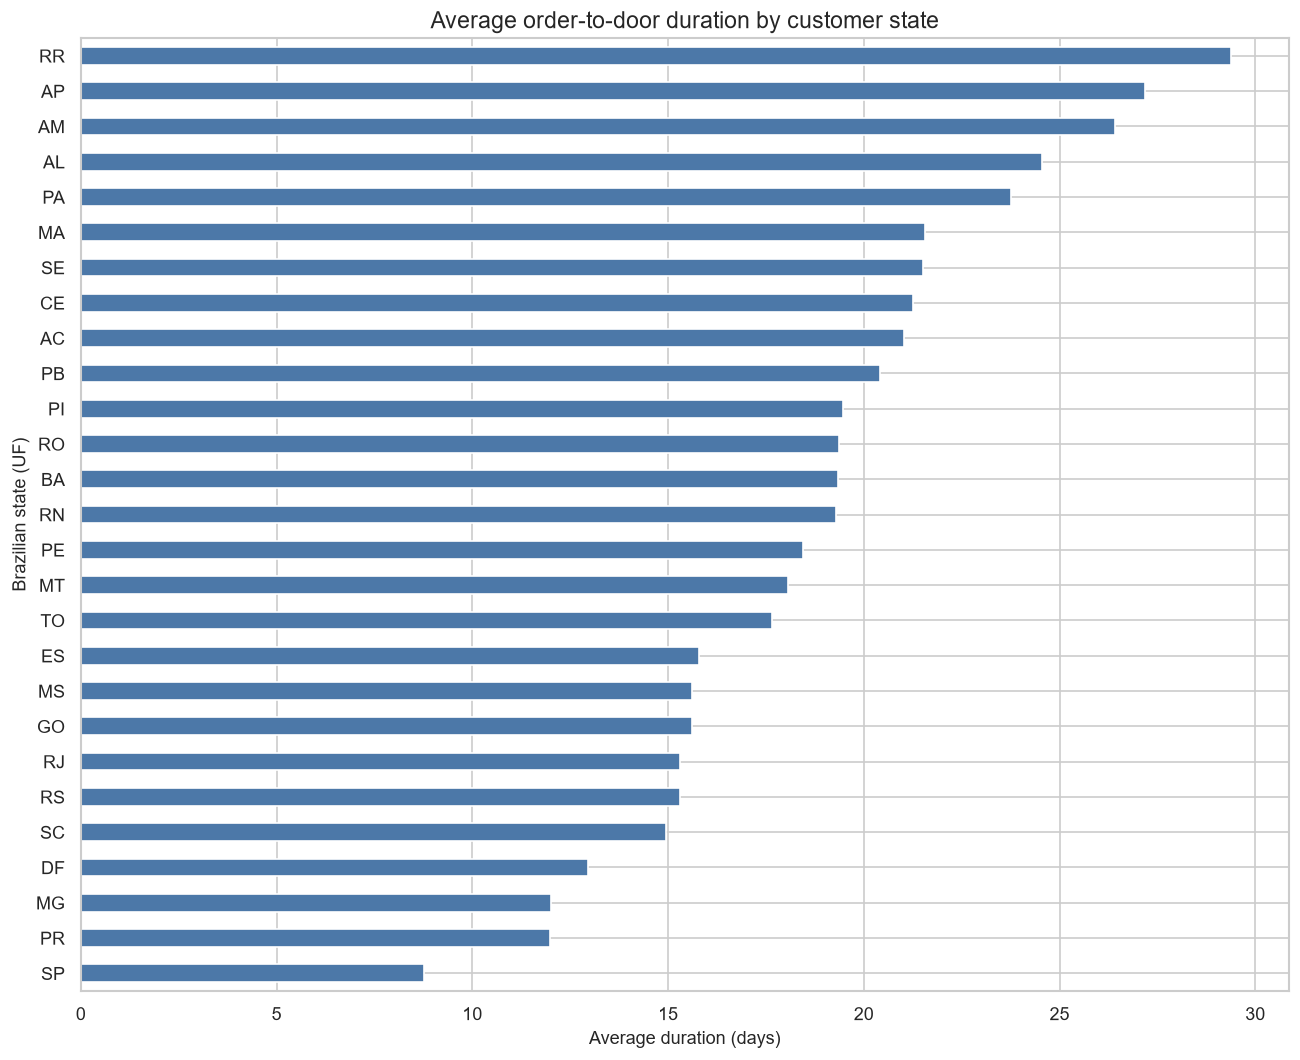

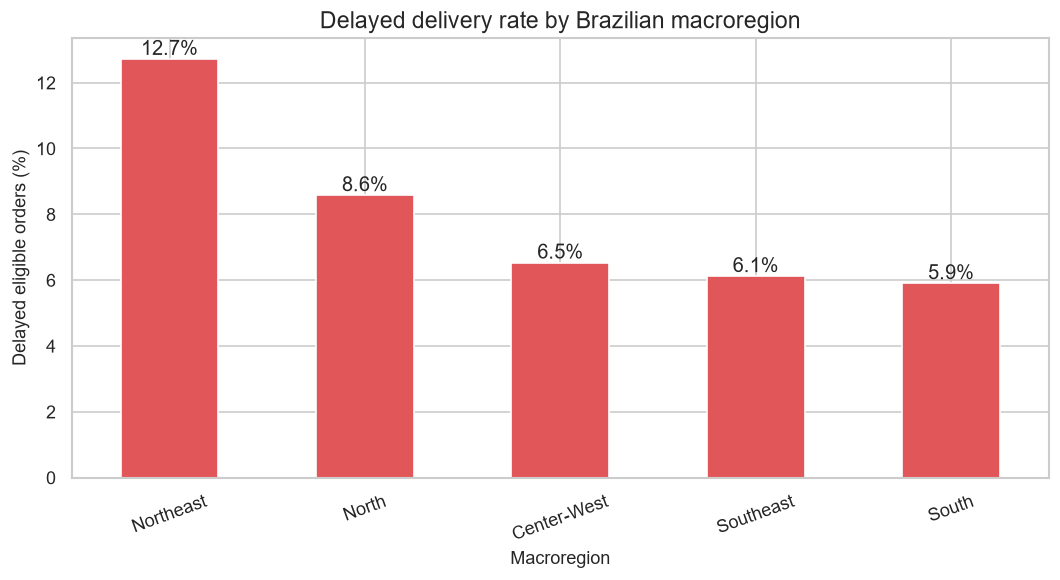

Northeast has the highest macroregion delay rate (12.7%, n=9,044); South has the lowest (5.9%, n=13,813).
AL has the highest state delay rate (21.4%, n=397); review sample size before prioritizing it.
Operational recommendation: prioritize regions with both elevated delay rates and sufficient order volume; validate local carrier and warehouse data before assigning root cause.
A choropleth is not produced: the loaded tables contain state codes but no boundary geometry or coordinates.


In [8]:
## State and Brazilian macroregion performance

uf_to_region = {
    'AC': 'North', 'AP': 'North', 'AM': 'North', 'PA': 'North', 'RO': 'North', 'RR': 'North', 'TO': 'North',
    'AL': 'Northeast', 'BA': 'Northeast', 'CE': 'Northeast', 'MA': 'Northeast', 'PB': 'Northeast',
    'PE': 'Northeast', 'PI': 'Northeast', 'RN': 'Northeast', 'SE': 'Northeast',
    'DF': 'Center-West', 'GO': 'Center-West', 'MT': 'Center-West', 'MS': 'Center-West',
    'ES': 'Southeast', 'MG': 'Southeast', 'RJ': 'Southeast', 'SP': 'Southeast',
    'PR': 'South', 'RS': 'South', 'SC': 'South',
}
analysis['customer_region'] = analysis['customer_state'].map(uf_to_region)
unmapped_states = sorted(analysis.loc[analysis['customer_state'].notna() & analysis['customer_region'].isna(), 'customer_state'].unique())
if unmapped_states:
    raise ValueError(f'Update the documented UF-to-region mapping for: {unmapped_states}')

state_summary = analysis.dropna(subset=['customer_state']).groupby('customer_state').agg(
    orders=('order_id', 'nunique'),
    average_duration_days=('delivery_duration_days', 'mean'),
    delayed_orders=('is_late', 'sum'),
    on_time_rate=('is_on_time', 'mean'),
)
state_summary['delay_rate_pct'] = 100 * state_summary['delayed_orders'] / state_summary['orders']
state_summary['on_time_rate_pct'] = 100 * state_summary['on_time_rate']
region_summary = analysis.dropna(subset=['customer_region']).groupby('customer_region').agg(
    orders=('order_id', 'nunique'),
    average_duration_days=('delivery_duration_days', 'mean'),
    delayed_orders=('is_late', 'sum'),
    on_time_rate=('is_on_time', 'mean'),
)
region_summary['delay_rate_pct'] = 100 * region_summary['delayed_orders'] / region_summary['orders']
region_summary['on_time_rate_pct'] = 100 * region_summary['on_time_rate']
display(state_summary.sort_values('delay_rate_pct', ascending=False).round(2))
display(region_summary.sort_values('delay_rate_pct', ascending=False).round(2))
print(f'Eligible orders with a state match: {int(analysis["customer_state"].notna().sum()):,} of {eligible_count:,}')

state_plot = state_summary.sort_values('average_duration_days')
fig, ax = plt.subplots(figsize=(11, 9))
state_plot['average_duration_days'].plot(kind='barh', ax=ax, color='#4C78A8')
ax.set(title='Average order-to-door duration by customer state', xlabel='Average duration (days)', ylabel='Brazilian state (UF)')
fig.tight_layout()
fig.savefig(CHART_DIR / 'state_average_delivery_duration.png', dpi=300, bbox_inches='tight')
plt.show()

region_plot = region_summary.sort_values('delay_rate_pct', ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
region_plot['delay_rate_pct'].plot(kind='bar', ax=ax, color='#E15759')
ax.set(title='Delayed delivery rate by Brazilian macroregion', xlabel='Macroregion', ylabel='Delayed eligible orders (%)')
ax.tick_params(axis='x', rotation=20)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%')
fig.tight_layout()
fig.savefig(CHART_DIR / 'regional_delivery_delay.png', dpi=300, bbox_inches='tight')
plt.show()

worst_region = region_summary['delay_rate_pct'].idxmax()
best_region = region_summary['delay_rate_pct'].idxmin()
worst_state = state_summary['delay_rate_pct'].idxmax()
print(f'{worst_region} has the highest macroregion delay rate ({region_summary.loc[worst_region, "delay_rate_pct"]:.1f}%, n={int(region_summary.loc[worst_region, "orders"]):,}); {best_region} has the lowest ({region_summary.loc[best_region, "delay_rate_pct"]:.1f}%, n={int(region_summary.loc[best_region, "orders"]):,}).')
print(f'{worst_state} has the highest state delay rate ({state_summary.loc[worst_state, "delay_rate_pct"]:.1f}%, n={int(state_summary.loc[worst_state, "orders"]):,}); review sample size before prioritizing it.')
print('Operational recommendation: prioritize regions with both elevated delay rates and sufficient order volume; validate local carrier and warehouse data before assigning root cause.')
print('A choropleth is not produced: the loaded tables contain state codes but no boundary geometry or coordinates.')

## Final validation and exports

Reconcile state and regional groups and list the high-resolution chart artifacts.

In [9]:
## Final validation and exported artifacts

assert int(analysis['order_id'].nunique()) == eligible_count, 'Customer join must preserve eligible order grain.'
assert int(state_summary['orders'].sum()) + int(analysis['customer_state'].isna().sum()) == eligible_count, 'State grouping must reconcile, including missing state rows.'
assert int(region_summary['orders'].sum()) == int(analysis['customer_region'].notna().sum()), 'Region totals must reconcile to mapped state rows.'
chart_files = sorted(CHART_DIR.glob('*.png'))
print(f'All reconciliation checks passed. Orders: {total_orders:,}; eligible: {eligible_count:,}; excluded: {excluded_from_kpis:,}.')
print(f'Charts exported ({len(chart_files)} files, saved at 300 DPI):')
for chart in chart_files:
    print(f'  - {chart.name}')
print('Findings above are computed from this dataset; review the reported denominators and data exclusions when interpreting them.')

All reconciliation checks passed. Orders: 99,441; eligible: 96,470; excluded: 2,971.
Charts exported (7 files, saved at 300 DPI):
  - duration_and_delivery_outcomes.png
  - kpi_summary.png
  - monthly_delivery_trends.png
  - regional_delivery_delay.png
  - seasonal_delivery_performance.png
  - state_average_delivery_duration.png
  - weekday_weekend_performance.png
Findings above are computed from this dataset; review the reported denominators and data exclusions when interpreting them.
